# 13 — Pretrained Robot Policies: LIBERO Benchmark

## 1. Environment Setup

In this notebook, we move from studying robot policy
architectures to evaluating pretrained policies on
realistic manipulation tasks.

We will use LIBERO, a simulation benchmark featuring
robotic manipulation tasks with visual observations
and natural-language instructions.

Our goals are:

1. Explore LIBERO tasks and observations.
2. Understand the robot's action space.
3. Load a compatible pretrained policy.
4. Execute closed-loop rollouts.
5. Measure task success and visualize trajectories.

In [3]:
import sys
import platform
import torch

print("Python:", sys.version.split()[0])
print("OS:", platform.platform())
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

    free, total = torch.cuda.mem_get_info()

    print(f"Total VRAM: {total / 1024**3:.2f} GiB")
    print(f"Free VRAM:  {free / 1024**3:.2f} GiB")

    device = torch.device("cuda")
else:
    device = torch.device("cpu")

print("Device:", device)

Python: 3.12.15
OS: Linux-7.0.0-31-generic-x86_64-with-glibc2.39
PyTorch: 2.10.0
CUDA available: True
GPU: NVIDIA GeForce RTX 3060 Laptop GPU
Total VRAM: 5.66 GiB
Free VRAM:  4.79 GiB
Device: cuda


## 2. Installing the LIBERO Benchmark

LeRobot integrates LIBERO and expose an interface to evalate policy.

It uses `hf-libero` which depends on MuJoCo.

In [4]:
from importlib.metadata import version, PackageNotFoundError

for package in [
    "lerobot",
    "torch",
    "transformers",
    "gymnasium",
    "mujoco",
    "robosuite",
    "libero",
]:
    try:
        print(f"{package:15s}: {version(package)}")
    except PackageNotFoundError:
        print(f"{package:15s}: not installed")

lerobot        : 0.6.1
torch          : 2.10.0
transformers   : 5.19.0
gymnasium      : 1.3.0
mujoco         : 3.8.1
robosuite      : 1.4.0
libero         : not installed


## 3. Exploring the LIBERO Benchmark

LIBERO is a benchmark for lifelong robot learning and
language-conditioned manipulation.

It provides simulated manipulation tasks involving a
robot arm, everyday objects, and natural-language
instructions.

LIBERO organizes tasks into several suites:

- **LIBERO-Spatial:** Spatial relationships and object positions.
- **LIBERO-Object:** Generalization across manipulated objects.
- **LIBERO-Goal:** Different goals and task objectives.
- **LIBERO-10:** A set of diverse manipulation tasks.
- **LIBERO-90:** A larger collection of manipulation tasks.

Each task defines:

1. A simulated environment.
2. An initial scene configuration.
3. A natural-language task description.
4. A success condition.

Our first goal is to inspect a task before executing
any robot policy.

In [3]:
from libero.libero import benchmark

benchmark_dict = benchmark.get_benchmark_dict()

print("Available benchmark suites:")
print(list(benchmark_dict.keys()))



Available benchmark suites:
['libero_spatial', 'libero_object', 'libero_goal', 'libero_90', 'libero_10', 'libero_100']


In [4]:
task_suite = benchmark_dict["libero_spatial"]()

print("Number of tasks:", task_suite.n_tasks)

for task_id in range(task_suite.n_tasks):
    task = task_suite.get_task(task_id)

    print(f"\nTask {task_id}")
    print("Name:", task.name)
    print("Language:", task.language)

[info] using task orders [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Number of tasks: 10

Task 0
Name: pick_up_the_black_bowl_between_the_plate_and_the_ramekin_and_place_it_on_the_plate
Language: pick up the black bowl between the plate and the ramekin and place it on the plate

Task 1
Name: pick_up_the_black_bowl_next_to_the_ramekin_and_place_it_on_the_plate
Language: pick up the black bowl next to the ramekin and place it on the plate

Task 2
Name: pick_up_the_black_bowl_from_table_center_and_place_it_on_the_plate
Language: pick up the black bowl from table center and place it on the plate

Task 3
Name: pick_up_the_black_bowl_on_the_cookie_box_and_place_it_on_the_plate
Language: pick up the black bowl on the cookie box and place it on the plate

Task 4
Name: pick_up_the_black_bowl_in_the_top_drawer_of_the_wooden_cabinet_and_place_it_on_the_plate
Language: pick up the black bowl in the top drawer of the wooden cabinet and place it on the plate

Task 5
Name: pick_up_the_black_bowl_on_the_ramekin_an

In [5]:
[name for name in dir(benchmark) if "benchmark" in name.lower()]

['BENCHMARK_MAPPING',
 'Benchmark',
 'get_benchmark',
 'get_benchmark_dict',
 'print_benchmark',
 'register_benchmark']

## 4. Creating a LIBERO Simulation Environment

We now instantiate a LIBERO manipulation task using
the MuJoCo simulator.

Each environment contains:

- A simulated robot manipulator.
- A gripper and manipulable objects.
- One or more RGB cameras.
- Robot proprioceptive observations.
- A task-specific success condition.

We will first inspect the observations returned by
the simulator before connecting a pretrained policy.

This is important because a robot policy must receive
observations in the format expected during training.

In [14]:
%env MUJOCO_GL=egl

env: MUJOCO_GL=egl


In [15]:
from libero.libero import get_libero_path
from libero.libero.envs import OffScreenRenderEnv
import os

task_id = 0
task = task_suite.get_task(task_id)

bddl_file = os.path.join(
    get_libero_path("bddl_files"),
    task.problem_folder,
    task.bddl_file,
)

print("Task:", task.language)
print("BDDL:", bddl_file)
print("File exists:", os.path.isfile(bddl_file))

env_args = {
    "bddl_file_name": bddl_file,
    "camera_heights": 256,
    "camera_widths": 256,
}

env = OffScreenRenderEnv(**env_args)
env.seed(42)

obs = env.reset()

print("\nEnvironment created successfully!")

/home/terreran/playground_ws/robot-learning-playground/.pixi/envs/cuda/lib/python3.12/site-packages/robosuite/__init__.py:33: SyntaxWarning: invalid escape sequence '\ '
  /[_]\  [~]\/    |//  |
[robosuite WARNING] No private macro file found! (__init__.py:7)
[robosuite WARNING] It is recommended to use a private macro file (__init__.py:8)
[robosuite WARNING] To setup, run: python /home/terreran/playground_ws/robot-learning-playground/.pixi/envs/cuda/lib/python3.12/site-packages/robosuite/scripts/setup_macros.py (__init__.py:9)


Task: pick up the black bowl between the plate and the ramekin and place it on the plate
BDDL: /home/terreran/playground_ws/robot-learning-playground/.pixi/envs/cuda/lib/python3.12/site-packages/libero/libero/./bddl_files/libero_spatial/pick_up_the_black_bowl_between_the_plate_and_the_ramekin_and_place_it_on_the_plate.bddl
File exists: True


/home/terreran/playground_ws/robot-learning-playground/.pixi/envs/cuda/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Local assets not found. Downloading from HuggingFace Hub...


/home/terreran/playground_ws/robot-learning-playground/.pixi/envs/cuda/lib/python3.12/site-packages/huggingface_hub/utils/_validators.py:208: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `snapshot_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
Fetching 586 files: 100%|██████████| 586/586 [00:29<00:00, 19.93it/s]


Assets downloaded successfully to /home/terreran/.cache/libero/assets

Environment created successfully!


In [16]:
import numpy as np

print("Observation keys:\n")

for key, value in obs.items():
    if isinstance(value, np.ndarray):
        print(
            f"{key:35s} "
            f"shape={str(value.shape):18s} "
            f"dtype={value.dtype}"
        )
    else:
        print(key, type(value))

Observation keys:

robot0_joint_pos                    shape=(7,)               dtype=float64
robot0_joint_pos_cos                shape=(7,)               dtype=float64
robot0_joint_pos_sin                shape=(7,)               dtype=float64
robot0_joint_vel                    shape=(7,)               dtype=float64
robot0_eef_pos                      shape=(3,)               dtype=float64
robot0_eef_quat                     shape=(4,)               dtype=float64
robot0_gripper_qpos                 shape=(2,)               dtype=float64
robot0_gripper_qvel                 shape=(2,)               dtype=float64
agentview_image                     shape=(256, 256, 3)      dtype=uint8
robot0_eye_in_hand_image            shape=(256, 256, 3)      dtype=uint8
akita_black_bowl_1_pos              shape=(3,)               dtype=float64
akita_black_bowl_1_quat             shape=(4,)               dtype=float64
akita_black_bowl_1_to_robot0_eef_pos shape=(3,)               dtype=float64
akita_bla

Available cameras: ['agentview_image', 'robot0_eye_in_hand_image']


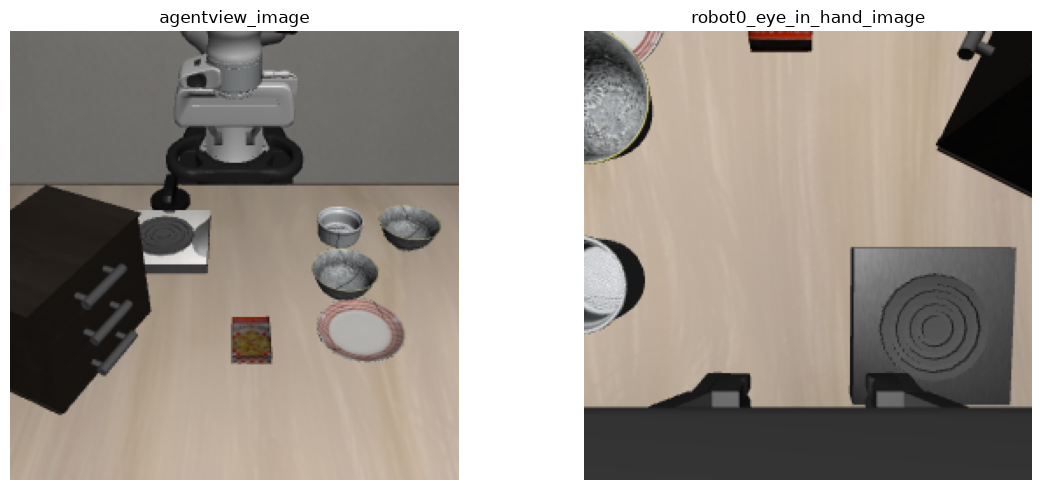

In [17]:
import matplotlib.pyplot as plt

camera_keys = [
    key for key, value in obs.items()
    if isinstance(value, np.ndarray)
    and value.ndim == 3
    and value.shape[-1] == 3
]

print("Available cameras:", camera_keys)

fig, axes = plt.subplots(
    1,
    len(camera_keys),
    figsize=(6 * len(camera_keys), 5),
    squeeze=False,
)

for ax, key in zip(axes[0], camera_keys):
    # LIBERO/Robosuite images are typically vertically flipped
    image = np.flipud(obs[key])

    ax.imshow(image)
    ax.set_title(key)
    ax.axis("off")

plt.tight_layout()
plt.show()

## 5. Understanding the LIBERO Action Space

LIBERO uses a simulated robot manipulator controlled
through an operational-space controller (OSC).

In the standard configuration, the policy predicts
a 7-dimensional action vector:

$$
a_t =
[\Delta x,\Delta y,\Delta z,
\Delta r_x,\Delta r_y,\Delta r_z,g]
$$

The action contains:

- **Translation (3D):** Desired end-effector displacement.
- **Rotation (3D):** Desired change in end-effector orientation.
- **Gripper (1D):** Command to open or close the gripper.

These values are typically normalized controller
commands, not necessarily displacements in meters
or rotations in radians.

The operational-space controller converts them into
joint-level commands.

Our goal is to inspect the actual action space and
observe how the robot responds to simple commands.

In [19]:
import numpy as np

print("Wrapper type:", type(env))

# Access the underlying Robosuite environment
sim_env = env.env

print("Underlying environment:", type(sim_env))

print("\nAction space:")
print("Action dimension:", sim_env.action_dim)

low, high = sim_env.action_spec

print("Lower bounds:", low)
print("Upper bounds:", high)

print("\nRobot:")
print("Robot name:", sim_env.robots[0].name)
print("Controller:", type(sim_env.robots[0].controller).__name__)

Wrapper type: <class 'libero.libero.envs.env_wrapper.OffScreenRenderEnv'>
Underlying environment: <class 'libero.libero.envs.problems.libero_tabletop_manipulation.Libero_Tabletop_Manipulation'>

Action space:
Action dimension: 7
Lower bounds: [-1. -1. -1. -1. -1. -1. -1.]
Upper bounds: [1. 1. 1. 1. 1. 1. 1.]

Robot:
Robot name: MountedPanda
Controller: OperationalSpaceController


In [20]:
print("Robot-related observations:\n")

for key, value in obs.items():
    if "robot" in key or "eef" in key or "gripper" in key:
        if isinstance(value, np.ndarray):
            print(f"{key:35s} {value.shape}")

Robot-related observations:

robot0_joint_pos                    (7,)
robot0_joint_pos_cos                (7,)
robot0_joint_pos_sin                (7,)
robot0_joint_vel                    (7,)
robot0_eef_pos                      (3,)
robot0_eef_quat                     (4,)
robot0_gripper_qpos                 (2,)
robot0_gripper_qvel                 (2,)
robot0_eye_in_hand_image            (256, 256, 3)
akita_black_bowl_1_to_robot0_eef_pos (3,)
akita_black_bowl_1_to_robot0_eef_quat (4,)
akita_black_bowl_2_to_robot0_eef_pos (3,)
akita_black_bowl_2_to_robot0_eef_quat (4,)
cookies_1_to_robot0_eef_pos         (3,)
cookies_1_to_robot0_eef_quat        (4,)
glazed_rim_porcelain_ramekin_1_to_robot0_eef_pos (3,)
glazed_rim_porcelain_ramekin_1_to_robot0_eef_quat (4,)
plate_1_to_robot0_eef_pos           (3,)
plate_1_to_robot0_eef_quat          (4,)
robot0_proprio-state                (39,)


In [22]:
# Reset simulation
obs = env.reset()

initial_eef_pos = obs["robot0_eef_pos"].copy()

print("Initial EEF position:", initial_eef_pos)

# Small command along the X axis
action = np.zeros(sim_env.action_dim, dtype=np.float32)
action[0] = 0.2

# Hold the gripper open (verify convention before grasping)
action[-1] = -1.0

eef_positions = [initial_eef_pos.copy()]

for _ in range(10):
    obs, reward, done, info = env.step(action)

    eef_positions.append(
        obs["robot0_eef_pos"].copy()
    )

    if done:
        break

eef_positions = np.array(eef_positions)

print("Final EEF position:", eef_positions[-1])
print("Displacement:", eef_positions[-1] - eef_positions[0])

Initial EEF position: [-0.20846466  0.          1.17327948]
Final EEF position: [-1.88245586e-01  9.79426634e-10  1.16981227e+00]
Displacement: [ 2.02190748e-02  9.79426634e-10 -3.46720776e-03]


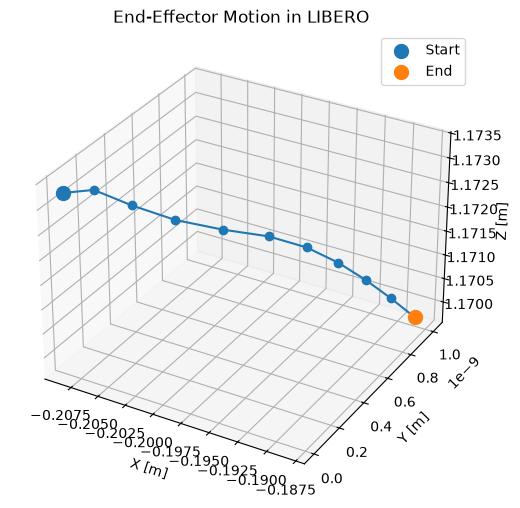

In [23]:
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(111, projection="3d")

ax.plot(
    eef_positions[:, 0],
    eef_positions[:, 1],
    eef_positions[:, 2],
    marker="o",
)

ax.scatter(
    *eef_positions[0],
    s=100,
    label="Start",
)

ax.scatter(
    *eef_positions[-1],
    s=100,
    label="End",
)

ax.set_xlabel("X [m]")
ax.set_ylabel("Y [m]")
ax.set_zlabel("Z [m]")

ax.set_title("End-Effector Motion in LIBERO")
ax.legend()

plt.show()

## 6. Recording a LIBERO Rollout

A robot rollout is a sequence of interactions between
a policy and an environment.

At each step:

1. The policy receives the current observation.
2. It generates an action.
3. The environment executes the action.
4. The simulator advances its physics.
5. A new observation is returned.

We first use a simple handcrafted policy to validate
the rollout pipeline.

Later, we will replace this policy with a pretrained
robot learning model.

The same evaluation loop will allow us to measure
task success and record robot behavior.

In [24]:
import numpy as np

def test_policy(obs, step, action_dim=7):
    action = np.zeros(action_dim, dtype=np.float32)

    if step < 20:
        action[0] = 0.2

    elif step < 40:
        action[1] = 0.2

    action[-1] = -1.0

    return action

In [25]:
obs = env.reset()

frames = []
eef_trajectory = []
rewards = []

num_steps = 60

for step in range(num_steps):

    action = test_policy(
        obs,
        step,
        action_dim=sim_env.action_dim,
    )

    obs, reward, done, info = env.step(action)

    frames.append(
        np.flipud(obs["agentview_image"]).copy()
    )

    eef_trajectory.append(
        obs["robot0_eef_pos"].copy()
    )

    rewards.append(reward)

    if done:
        print(f"Episode terminated at step {step}")
        break

frames = np.stack(frames)
eef_trajectory = np.stack(eef_trajectory)

print("Recorded frames:", frames.shape)
print("EEF trajectory:", eef_trajectory.shape)
print("Total reward:", sum(rewards))
print("Task success:", env.check_success())

Recorded frames: (60, 256, 256, 3)
EEF trajectory: (60, 3)
Total reward: 0.0
Task success: False


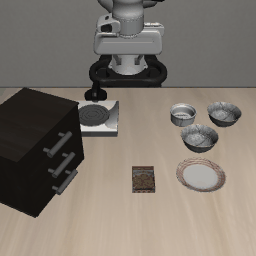

In [26]:
from IPython.display import display, Image
from PIL import Image as PILImage
import io

pil_frames = [
    PILImage.fromarray(frame)
    for frame in frames
]

buffer = io.BytesIO()

pil_frames[0].save(
    buffer,
    format="GIF",
    save_all=True,
    append_images=pil_frames[1:],
    duration=100,
    loop=0,
)

display(Image(data=buffer.getvalue()))

In [27]:
controller = sim_env.robots[0].controller

print("Controller:", type(controller).__name__)
print("Input reference frame:", getattr(controller, "input_ref_frame", "Not exposed"))

Controller: OperationalSpaceController
Input reference frame: Not exposed


## 7. Evaluating a Pretrained Robot Policy

We will first evaluate a pretrained ACT policy on LIBERO.

ACT combines:
- Visual feature extraction.
- Transformer-based action prediction.
- A conditional variational autoencoder.
- Temporal action chunking.

Unlike a general-purpose VLA, this policy is trained
for a specific manipulation task and does not use
language instructions.

Our goal is to reproduce a closed-loop rollout using
the official LeRobot evaluation interface.

Later, we will compare this approach with SmolVLA,
which incorporates language conditioning and flow matching.

In [28]:
from huggingface_hub import hf_hub_download
import json

model_id = "Harrysunshine/act-libero-goal"

config_path = hf_hub_download(
    repo_id=model_id,
    filename="config.json",
)

with open(config_path) as f:
    config = json.load(f)

print("Policy type:", config.get("type"))
print("Action chunk size:", config.get("chunk_size"))
print("Actions executed per chunk:", config.get("n_action_steps"))

print("\nInput features:")
for name, feature in config["input_features"].items():
    print(name, feature["shape"])

print("\nOutput features:")
for name, feature in config["output_features"].items():
    print(name, feature["shape"])

Policy type: act
Action chunk size: 100
Actions executed per chunk: 100

Input features:
observation.images.image [3, 256, 256]
observation.images.image2 [3, 256, 256]
observation.state [8]

Output features:
action [7]


## 8. Loading a Pretrained ACT Policy

We now load a pretrained Action Chunking Transformer (ACT)
using LeRobot.

The pretrained checkpoint contains the model architecture
configuration and learned neural network weights.

Our first goal is to:

1. Download and load the pretrained policy.
2. Move the model to the GPU.
3. Verify its input and output interfaces.
4. Inspect the preprocessing requirements.

We will not execute robot actions yet.

Before running inference, we must ensure that the
LIBERO observations are converted into exactly the
same representation used during training.

In [29]:
import torch
from lerobot.policies.act.modeling_act import ACTPolicy

model_id = "Harrysunshine/act-libero-goal"

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

policy = ACTPolicy.from_pretrained(model_id)

policy = policy.to(device)
policy.eval()

print("Device:", device)
print("Policy:", type(policy).__name__)

num_params = sum(
    p.numel() for p in policy.parameters()
)

print(f"Parameters: {num_params / 1e6:.2f} M")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /home/terreran/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 104MB/s] 


Device: cuda
Policy: ACTPolicy
Parameters: 51.60 M


In [30]:
if device.type == "cuda":

    allocated = torch.cuda.memory_allocated() / 1024**3
    reserved = torch.cuda.memory_reserved() / 1024**3

    print(f"GPU allocated: {allocated:.3f} GiB")
    print(f"GPU reserved:  {reserved:.3f} GiB")

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

GPU allocated: 0.193 GiB
GPU reserved:  0.211 GiB
GPU: NVIDIA GeForce RTX 3060 Laptop GPU


In [31]:
print("Input features:\n")

for name, feature in policy.config.input_features.items():
    print(name, feature)

print("\nOutput features:\n")

for name, feature in policy.config.output_features.items():
    print(name, feature)

print("\nChunk size:", policy.config.chunk_size)
print("Action steps:", policy.config.n_action_steps)

Input features:

observation.images.image PolicyFeature(type=<FeatureType.VISUAL: 'VISUAL'>, shape=(3, 256, 256))
observation.images.image2 PolicyFeature(type=<FeatureType.VISUAL: 'VISUAL'>, shape=(3, 256, 256))
observation.state PolicyFeature(type=<FeatureType.STATE: 'STATE'>, shape=(8,))

Output features:

action PolicyFeature(type=<FeatureType.ACTION: 'ACTION'>, shape=(7,))

Chunk size: 100
Action steps: 100


In [32]:
from huggingface_hub import list_repo_files

repo_files = list_repo_files(model_id)

print("Repository files:\n")

for filename in repo_files:
    print(filename)

Repository files:

.gitattributes
README.md
config.json
eval_summary.json
model.safetensors
policy_postprocessor.json
policy_postprocessor_step_0_unnormalizer_processor.safetensors
policy_preprocessor.json
policy_preprocessor_step_3_normalizer_processor.safetensors
train_config.json


## 9. Preprocessing and Postprocessing

A pretrained robot policy is more than a neural network.

During training, observations are transformed before
being passed to the model. Similarly, predicted actions
must be transformed back into the robot's action space.

The complete inference pipeline is:

$$
o_t
\xrightarrow{\text{preprocessor}}
\tilde{o}_t
\xrightarrow{\pi_\theta}
\tilde{a}_{t:t+H-1}
\xrightarrow{\text{postprocessor}}
a_{t:t+H-1}
$$

Where:

- $o_t$: Raw observations from the robot environment.
- $\tilde{o}_t$: Preprocessed and normalized observations.
- $\pi_\theta$: Pretrained robot policy.
- $\tilde{a}_{t:t+H-1}$: Predicted actions in the model's representation.
- $a_{t:t+H-1}$: Actions converted to the environment's control space.

The normalization statistics are learned from the
training dataset and saved alongside the model.

Using the correct preprocessing is essential for
reproducing the behavior of a pretrained policy.

In [33]:
from huggingface_hub import hf_hub_download
import json

for filename in [
    "policy_preprocessor.json",
    "policy_postprocessor.json",
]:
    path = hf_hub_download(
        repo_id=model_id,
        filename=filename,
    )

    with open(path) as f:
        data = json.load(f)

    print(f"\n{'=' * 60}")
    print(filename)
    print("=" * 60)

    print(json.dumps(data, indent=2))


policy_preprocessor.json
{
  "name": "policy_preprocessor",
  "steps": [
    {
      "registry_name": "rename_observations_processor",
      "config": {
        "rename_map": {}
      }
    },
    {
      "registry_name": "to_batch_processor",
      "config": {}
    },
    {
      "registry_name": "device_processor",
      "config": {
        "device": "cuda",
        "float_dtype": null
      }
    },
    {
      "registry_name": "normalizer_processor",
      "config": {
        "eps": 1e-08,
        "features": {
          "observation.images.image": {
            "type": "VISUAL",
            "shape": [
              3,
              256,
              256
            ]
          },
          "observation.images.image2": {
            "type": "VISUAL",
            "shape": [
              3,
              256,
              256
            ]
          },
          "observation.state": {
            "type": "STATE",
            "shape": [
              8
            ]
          },
 

In [34]:
train_config_path = hf_hub_download(
    repo_id=model_id,
    filename="train_config.json",
)

with open(train_config_path) as f:
    train_config = json.load(f)

print("Top-level keys:")
print(list(train_config.keys()))

Top-level keys:
['dataset', 'env', 'policy', 'output_dir', 'job_name', 'resume', 'seed', 'cudnn_deterministic', 'num_workers', 'batch_size', 'steps', 'eval_freq', 'log_freq', 'tolerance_s', 'save_checkpoint', 'save_freq', 'use_policy_training_preset', 'optimizer', 'scheduler', 'eval', 'wandb', 'peft', 'use_rabc', 'rabc_progress_path', 'rabc_kappa', 'rabc_epsilon', 'rabc_head_mode', 'rename_map', 'checkpoint_path']


In [35]:
for key, value in train_config.items():
    if any(
        word in key.lower()
        for word in ["dataset", "env", "policy"]
    ):
        print(f"\n{key}:")
        print(json.dumps(value, indent=2)[:3000])


dataset:
{
  "repo_id": "lerobot/libero",
  "root": null,
  "episodes": [
    379,
    422,
    426,
    431,
    433,
    447,
    448,
    451,
    459,
    466,
    481,
    483,
    488,
    507,
    511,
    513,
    522,
    532,
    537,
    549,
    551,
    563,
    568,
    582,
    607,
    615,
    620,
    621,
    626,
    634,
    639,
    642,
    646,
    653,
    655,
    670,
    679,
    708,
    716,
    718,
    726,
    727,
    749,
    750,
    768,
    770,
    801,
    803,
    806
  ],
  "image_transforms": {
    "enable": false,
    "max_num_transforms": 3,
    "random_order": false,
    "tfs": {
      "brightness": {
        "weight": 1.0,
        "type": "ColorJitter",
        "kwargs": {
          "brightness": [
            0.8,
            1.2
          ]
        }
      },
      "contrast": {
        "weight": 1.0,
        "type": "ColorJitter",
        "kwargs": {
          "contrast": [
            0.8,
            1.2
          ]
        }
      }

In [36]:
from huggingface_hub import hf_hub_download

readme_path = hf_hub_download(
    repo_id=model_id,
    filename="README.md",
)

with open(readme_path) as f:
    readme = f.read()

print(readme)

---
license: apache-2.0
library_name: lerobot
pipeline_tag: robotics
tags:
  - robotics
  - lerobot
  - act
  - libero
  - imitation-learning
  - manipulation
datasets:
  - lerobot/libero
---

# ACT — LIBERO-Goal "put the bowl on the plate"

An [ACT](https://arxiv.org/abs/2304.13705) (Action Chunking Transformer) policy trained with
[LeRobot](https://github.com/huggingface/lerobot) on a **single LIBERO-Goal task**:
`put the bowl on the plate` (task suite `libero_goal`, `task_id = 8`).

It reaches **100% success rate (10/10 episodes)** on that task in the LIBERO simulator.

This checkpoint was produced as a teaching demo for a robot-learning course: it is small
(51.7M parameters), trains in minutes on one GPU, and is meant as a clean, reproducible
reference point for "what a working single-task imitation policy looks like".

## Model details

| | |
|---|---|
| Policy | ACT (CVAE + action chunking), `lerobot` `type: act` |
| Parameters | 51,671,687 (fp32, 234 tensors) |
| Vision backbone

In [37]:
import json

eval_path = hf_hub_download(
    repo_id=model_id,
    filename="eval_summary.json",
)

with open(eval_path) as f:
    eval_summary = json.load(f)

print(json.dumps(eval_summary, indent=2)[:6000])

{
  "_runtime": 17838.92236567,
  "eval/steps": 950,
  "eval/episodes": 2611.615165461319,
  "eval/epochs": 53.298268682884064,
  "eval/pc_success": 100,
  "eval/eval_s": 26.246055364608765,
  "_timestamp": 1775761646.6205258,
  "eval/samples": 243200,
  "eval/avg_sum_reward": 1,
  "eval/video": {
    "_type": "video-file",
    "sha256": "975bc23d995f7ddaaf91a71722cca626ee93d29bcb8119a24d2274eedd230467",
    "size": 26056,
    "path": "media/videos/eval/video_950_975bc23d995f7ddaaf91.mp4"
  },
  "_step": 950,
  "train/samples": 243200,
  "train/episodes": 2611.615165461319,
  "train/epochs": 53.298268682884064,
  "train/l1_loss": 0.13706612586975098,
  "train/steps": 950,
  "train/loss": 0.39539810419082644,
  "train/grad_norm": 9.418527030944825,
  "train/lr": 1e-05,
  "train/update_s": 0.26275435017887505,
  "train/dataloading_s": 0.00797693240456283,
  "train/kld_loss": 0.02563200518488884
}


In [38]:
suite = benchmark_dict["libero_goal"]()
task = suite.get_task(8)

print(task.language)

[info] using task orders [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
put the bowl on the plate


## 10. Mapping LIBERO Observations to ACT Inputs

A pretrained policy expects observations in the same
representation used during training.

Our ACT checkpoint expects:

- Two RGB images with shape `(3, 256, 256)`.
- A robot state vector with 8 elements.
- A 7-dimensional action space.

LIBERO exposes a richer observation dictionary containing
camera images, joint states, end-effector poses, and gripper states.

We must map these observations to the policy input format.

An incorrect mapping may produce valid tensors but
incorrect robot behavior.

We will inspect the observation structure and the
training configuration before running inference.

In [39]:
obs = env.reset()

state_keys = [
    "robot0_eef_pos",
    "robot0_eef_quat",
    "robot0_gripper_qpos",
    "robot0_gripper_qvel",
    "robot0_joint_pos",
    "robot0_joint_vel",
]

for key in state_keys:
    if key in obs:
        value = np.asarray(obs[key])
        print(f"{key:25s} shape={value.shape}")
        print(" ", value)

robot0_eef_pos            shape=(3,)
  [-0.20846466  0.          1.17327948]
robot0_eef_quat           shape=(4,)
  [ 9.99596605e-01  2.46212832e-04 -2.84001205e-02 -6.99529596e-06]
robot0_gripper_qpos       shape=(2,)
  [ 0.020833 -0.020833]
robot0_gripper_qvel       shape=(2,)
  [0. 0.]
robot0_joint_pos          shape=(7,)
  [ 0.         -0.16103739  0.         -2.44459747  0.          2.2267522
  0.78539816]
robot0_joint_vel          shape=(7,)
  [0. 0. 0. 0. 0. 0. 0.]


In [40]:
print("Dataset configuration:")

dataset_config = train_config.get("dataset", {})

for key, value in dataset_config.items():
    if key != "episodes":
        print(f"{key}: {value}")

Dataset configuration:
repo_id: lerobot/libero
root: None
image_transforms: {'enable': False, 'max_num_transforms': 3, 'random_order': False, 'tfs': {'brightness': {'weight': 1.0, 'type': 'ColorJitter', 'kwargs': {'brightness': [0.8, 1.2]}}, 'contrast': {'weight': 1.0, 'type': 'ColorJitter', 'kwargs': {'contrast': [0.8, 1.2]}}, 'saturation': {'weight': 1.0, 'type': 'ColorJitter', 'kwargs': {'saturation': [0.5, 1.5]}}, 'hue': {'weight': 1.0, 'type': 'ColorJitter', 'kwargs': {'hue': [-0.05, 0.05]}}, 'sharpness': {'weight': 1.0, 'type': 'SharpnessJitter', 'kwargs': {'sharpness': [0.5, 1.5]}}, 'affine': {'weight': 1.0, 'type': 'RandomAffine', 'kwargs': {'degrees': [-5.0, 5.0], 'translate': [0.05, 0.05]}}}}
revision: None
use_imagenet_stats: False
video_backend: pyav
streaming: False


In [41]:
print("\nDataset-related configuration keys:")

for key in train_config:
    if any(
        term in key.lower()
        for term in ["rename", "transform", "feature", "processor"]
    ):
        print(key)
        print(str(train_config[key])[:1500])


Dataset-related configuration keys:
rename_map
{}


In [42]:
from huggingface_hub import hf_hub_download
import json

dataset_id = "lerobot/libero"

info_path = hf_hub_download(
    repo_id=dataset_id,
    repo_type="dataset",
    filename="meta/info.json",
)

with open(info_path) as f:
    dataset_info = json.load(f)

print("Dataset features:\n")

for name, feature in dataset_info["features"].items():
    print(name, feature)

Dataset features:

observation.images.image {'dtype': 'video', 'shape': [256, 256, 3], 'names': ['height', 'width', 'channel'], 'fps': 10.0, 'info': {'video.height': 256, 'video.width': 256, 'video.codec': 'av1', 'video.pix_fmt': 'yuv420p', 'video.is_depth_map': False, 'video.fps': 10, 'video.channels': 3, 'has_audio': False}}
observation.images.image2 {'dtype': 'video', 'shape': [256, 256, 3], 'names': ['height', 'width', 'channel'], 'fps': 10.0, 'info': {'video.height': 256, 'video.width': 256, 'video.codec': 'av1', 'video.pix_fmt': 'yuv420p', 'video.is_depth_map': False, 'video.fps': 10, 'video.channels': 3, 'has_audio': False}}
observation.state {'dtype': 'float32', 'shape': [8], 'names': ['state'], 'fps': 10.0}
action {'dtype': 'float32', 'shape': [7], 'names': ['actions'], 'fps': 10.0}
timestamp {'dtype': 'float32', 'shape': [1], 'names': None}
frame_index {'dtype': 'int64', 'shape': [1], 'names': None}
episode_index {'dtype': 'int64', 'shape': [1], 'names': None}
index {'dtype':

## 11. Inspecting the LIBERO Observation Adapter

The dataset metadata specifies the shape of each feature,
but does not fully describe its semantic content.

In particular, `observation.state` is an 8-dimensional
vector whose components must match the representation
used during training.

We will inspect LeRobot's LIBERO environment adapter
to identify:

- The two camera mappings.
- The robot state representation.
- Image preprocessing conventions.
- The conversion between LIBERO and LeRobot observations.

This avoids guessing the observation format.

In [43]:
import inspect
import lerobot.envs.libero as libero_adapter

print("Adapter file:")
print(inspect.getfile(libero_adapter))

print("\nAvailable functions and classes:")

for name, obj in inspect.getmembers(libero_adapter):
    if (
        inspect.isfunction(obj)
        or inspect.isclass(obj)
    ):
        if obj.__module__ == libero_adapter.__name__:
            print(name)

Adapter file:
/home/terreran/playground_ws/robot-learning-playground/.pixi/envs/cuda/lib/python3.12/site-packages/lerobot/envs/libero.py

Available functions and classes:
LiberoEnv
_get_suite
_make_env_fns
_select_task_ids
create_libero_envs
get_libero_dummy_action
get_task_init_states


In [44]:
source = inspect.getsource(libero_adapter)

for term in [
    "robot0_eef_pos",
    "robot0_eef_quat",
    "robot0_gripper_qpos",
    "observation.state",
    "agentview_image",
]:
    print(f"{term}: {term in source}")

robot0_eef_pos: True
robot0_eef_quat: True
robot0_gripper_qpos: True
observation.state: False
agentview_image: True


In [45]:
lines = source.splitlines()

for i, line in enumerate(lines):
    if "robot0_eef_pos" in line:
        start = max(0, i - 8)
        end = min(len(lines), i + 15)

        print("\n".join(
            f"{j + 1:4d}: {lines[j]}"
            for j in range(start, end)
        ))

 286: 
 287:     def _format_raw_obs(self, raw_obs: RobotObservation) -> RobotObservation:
 288:         assert self._env is not None, "_format_raw_obs called before _ensure_env()"
 289:         images = {}
 290:         for camera_name in self.camera_name:
 291:             image = raw_obs[camera_name]
 292:             images[self.camera_name_mapping[camera_name]] = image
 293: 
 294:         eef_pos = raw_obs.get("robot0_eef_pos")
 295:         eef_quat = raw_obs.get("robot0_eef_quat")
 296: 
 297:         # rotation matrix from controller
 298:         eef_mat = self._env.robots[0].controller.ee_ori_mat if eef_pos is not None else None
 299:         gripper_qpos = raw_obs.get("robot0_gripper_qpos")
 300:         gripper_qvel = raw_obs.get("robot0_gripper_qvel")
 301:         joint_pos = raw_obs.get("robot0_joint_pos")
 302:         joint_vel = raw_obs.get("robot0_joint_vel")
 303:         obs = {
 304:             "pixels": images,
 305:             "robot_state": {
 306:          

In [46]:
import inspect
import lerobot.envs.libero as libero_adapter

source = inspect.getsource(libero_adapter)
lines = source.splitlines()

keywords = [
    "observation.state",
    "robot_state",
    "state =",
    "concatenate",
    "camera_name_mapping",
]

for i, line in enumerate(lines):
    if any(keyword in line for keyword in keywords):
        print(f"{i + 1:4d}: {line}")

 126:         camera_name_mapping: dict[str, str] | None = None,
 156:         if camera_name_mapping is None:
 157:             camera_name_mapping = {
 161:         self.camera_name_mapping = camera_name_mapping
 197:             images[self.camera_name_mapping[cam]] = spaces.Box(
 220:                     "robot_state": spaces.Dict(
 292:             images[self.camera_name_mapping[camera_name]] = image
 305:             "robot_state": {
 414:     camera_name_mapping: dict[str, str] | None = None,
 431:             camera_name_mapping=camera_name_mapping,
 454:     camera_name_mapping: dict[str, str] | None = None,
 514:                 camera_name_mapping=camera_name_mapping,


In [47]:
for i in range(300, min(350, len(lines))):
    print(f"{i + 1:4d}: {lines[i]}")

 301:         joint_pos = raw_obs.get("robot0_joint_pos")
 302:         joint_vel = raw_obs.get("robot0_joint_vel")
 303:         obs = {
 304:             "pixels": images,
 305:             "robot_state": {
 306:                 "eef": {
 307:                     "pos": eef_pos,  # (3,)
 308:                     "quat": eef_quat,  # (4,)
 309:                     "mat": eef_mat,  # (3, 3)
 310:                 },
 311:                 "gripper": {
 312:                     "qpos": gripper_qpos,  # (2,)
 313:                     "qvel": gripper_qvel,  # (2,)
 314:                 },
 315:                 "joints": {
 316:                     "pos": joint_pos,  # (7,)
 317:                     "vel": joint_vel,  # (7,)
 318:                 },
 319:             },
 320:         }
 321:         if self.obs_type == "pixels":
 322:             return {"pixels": images.copy()}
 323: 
 324:         if self.obs_type == "pixels_agent_pos":
 325:             # Validate required fields are pres

In [50]:
from pathlib import Path
import lerobot

lerobot_path = Path(lerobot.__file__).parent

matches = []

for path in lerobot_path.rglob("*.py"):
    text = path.read_text(encoding="utf-8")

    if "def preprocess_observation(" in text:
        matches.append(path.relative_to(lerobot_path))

print("Definitions found:")
for path in matches:
    print(path)

Definitions found:
envs/utils.py


In [51]:
import inspect
from lerobot.envs.utils import preprocess_observation

print(inspect.getsource(preprocess_observation))



def preprocess_observation(observations: dict[str, np.ndarray]) -> dict[str, Tensor]:
    # TODO(jadechoghari, imstevenpmwork): refactor this to use features from the environment (no hardcoding)
    """Convert environment observation to LeRobot format observation.
    Args:
        observation: Dictionary of observation batches from a Gym vector environment.
    Returns:
        Dictionary of observation batches with keys renamed to LeRobot format and values as tensors.
    """
    # map to expected inputs for the policy
    return_observations = {}
    if "pixels" in observations:
        if isinstance(observations["pixels"], dict):
            imgs = {f"{OBS_IMAGES}.{key}": img for key, img in observations["pixels"].items()}
        else:
            imgs = {OBS_IMAGE: observations["pixels"]}

        for imgkey, img in imgs.items():
            # TODO(aliberts, rcadene): use transforms.ToTensor()?
            img_tensor = torch.from_numpy(img)

            # When preprocessing obser

In [52]:
import inspect
import lerobot.envs.libero as libero_adapter

source = inspect.getsource(libero_adapter)
lines = source.splitlines()

keywords = [
    "agent_pos",
    "get_env_processors",
    "processor",
    "eef.pos",
    "gripper.qpos",
]

for i, line in enumerate(lines):
    if any(keyword in line for keyword in keywords):
        print(f"{i + 1:4d}: {line.strip()}")



 207: "Please switch to an image-based obs_type (e.g. 'pixels', 'pixels_agent_pos')."
 216: elif self.obs_type == "pixels_agent_pos":
 324: if self.obs_type == "pixels_agent_pos":
 336: "Please switch to an image-based obs_type (e.g. 'pixels', 'pixels_agent_pos')."


### Inspecting Recorded Robot States

The pretrained ACT policy expects an 8-dimensional
robot state, but the current LIBERO adapter exposes
a structured observation.

We will inspect a recorded demonstration to understand
the numerical representation used during training.

This helps us compare the dataset representation with
the simulator's raw observations before implementing
the policy input mapping.

In [53]:
training_episode = train_config["dataset"]["episodes"][0]

print("Training episode:", training_episode)

print("Dataset metadata keys:")
print(dataset_info.keys())

print("\nAvailable episode metadata:")
print(dataset_info.get("data_path"))

Training episode: 379
Dataset metadata keys:
dict_keys(['codebase_version', 'robot_type', 'total_episodes', 'total_frames', 'total_tasks', 'chunks_size', 'data_files_size_in_mb', 'video_files_size_in_mb', 'fps', 'splits', 'data_path', 'video_path', 'features'])

Available episode metadata:
data/chunk-{chunk_index:03d}/file-{file_index:03d}.parquet


In [54]:
from lerobot.datasets.lerobot_dataset import LeRobotDataset

dataset = LeRobotDataset(
    repo_id="lerobot/libero",
    episodes=[training_episode],
    video_backend="pyav",
)

sample = dataset[0]

print("Sample keys:")
for key, value in sample.items():
    print(key, getattr(value, "shape", type(value)))

print("\nRecorded robot state:")
print(sample["observation.state"])

Fetching 3 files: 100%|██████████| 3/3 [00:01<00:00,  1.99it/s]

Sample keys:
observation.images.image torch.Size([3, 256, 256])
observation.images.image2 torch.Size([3, 256, 256])
observation.state torch.Size([8])
action torch.Size([7])
timestamp torch.Size([])
frame_index torch.Size([])
episode_index torch.Size([])
index torch.Size([])
task_index torch.Size([])
task <class 'str'>

Recorded robot state:
tensor([-0.2030,  0.0103,  1.1777,  3.1398,  0.0043, -0.0928,  0.0388, -0.0388])


## 12. Reconstructing the LIBERO Robot State

The pretrained ACT checkpoint expects an 8-dimensional
robot state.

By inspecting a recorded demonstration, we identified
a likely representation:

$$
s_t =
[\mathbf{p}_{eef},
\mathbf{r}_{eef},
\mathbf{q}_{gripper}]
$$

where:

- $\mathbf{p}_{eef} \in \mathbb{R}^3$: End-effector position.
- $\mathbf{r}_{eef} \in \mathbb{R}^3$: Axis-angle orientation.
- $\mathbf{q}_{gripper} \in \mathbb{R}^2$: Gripper joint positions.

We will compare this representation with the raw
observations provided by the LIBERO simulator.

The numerical similarity is evidence for the mapping,
but the rotation convention must still be verified.

In [55]:
import numpy as np
from scipy.spatial.transform import Rotation

obs = env.reset()

eef_pos = obs["robot0_eef_pos"]
eef_quat = obs["robot0_eef_quat"]
gripper_qpos = obs["robot0_gripper_qpos"]

# Use the end-effector orientation matrix exposed
# by the same controller used in the LIBERO adapter.
eef_mat = sim_env.robots[0].controller.ee_ori_mat

eef_rotvec = Rotation.from_matrix(eef_mat).as_rotvec()

state_8d = np.concatenate([
    eef_pos,
    eef_rotvec,
    gripper_qpos,
]).astype(np.float32)

print("EEF position:", eef_pos)
print("EEF quaternion:", eef_quat)
print("EEF rotation vector:", eef_rotvec)
print("Gripper qpos:", gripper_qpos)

print("\nReconstructed state:")
print(state_8d)

print("\nDataset example:")
print(sample["observation.state"].numpy())


EEF position: [-0.20846466  0.          1.17327948]
EEF quaternion: [ 9.99596605e-01  2.46212832e-04 -2.84001205e-02 -6.99529596e-06]
EEF rotation vector: [-2.1920501  -2.19313023  0.06227961]
Gripper qpos: [ 0.020833 -0.020833]

Reconstructed state:
[-0.20846467  0.          1.1732795  -2.1920502  -2.1931303   0.06227961
  0.020833   -0.020833  ]

Dataset example:
[-0.20300905  0.01033242  1.177666    3.1398387   0.00431274 -0.09276684
  0.0387873  -0.03878865]


### 12.1 Comparing End-Effector Orientation Representations

LIBERO exposes the end-effector orientation through
both the robot observation and the OSC controller.

These representations may use different reference frames
or conventions.

We will convert both orientations to rotation matrices
and compare them.

The goal is to identify which representation is
consistent with the robot state used during training.

In [56]:
import numpy as np
from scipy.spatial.transform import Rotation

obs = env.reset()

eef_quat = obs["robot0_eef_quat"]
eef_mat = sim_env.robots[0].controller.ee_ori_mat.copy()

# Robosuite observations typically use XYZW quaternions.
rot_from_quat = Rotation.from_quat(eef_quat)
rot_from_mat = Rotation.from_matrix(eef_mat)

print("Rotation vector from observation quaternion:")
print(rot_from_quat.as_rotvec())

print("\nRotation vector from controller matrix:")
print(rot_from_mat.as_rotvec())

print("\nRotation matrix from quaternion:")
print(rot_from_quat.as_matrix())

print("\nRotation matrix from controller:")
print(rot_from_mat.as_matrix())

# Relative rotation between the two orientations
relative_rotation = rot_from_quat.inv() * rot_from_mat

print("\nRelative rotation angle [degrees]:")
print(np.degrees(relative_rotation.magnitude()))

Rotation vector from observation quaternion:
[-3.14031137e+00 -7.73496979e-04  8.92212125e-02]

Rotation vector from controller matrix:
[-2.1920501  -2.19313023  0.06227961]

Rotation matrix from quaternion:
[[ 9.98386745e-01  4.91829687e-04 -5.67773315e-02]
 [ 4.92624356e-04 -9.99999879e-01 -8.14845695e-19]
 [-5.67773246e-02 -2.79698964e-05 -9.98386866e-01]]

Rotation matrix from controller:
[[-4.91829687e-04  9.98386745e-01 -5.67773315e-02]
 [ 9.99999879e-01  4.92624356e-04 -2.08166817e-17]
 [ 2.79698964e-05 -5.67773246e-02 -9.98386866e-01]]

Relative rotation angle [degrees]:
90.00000000000004


### 12.2 Comparing Rotations in SO(3)

Rotation vectors are not unique representations of orientation.

In particular, rotations close to 180 degrees may have
rotation vectors with very different signs.

Instead of comparing their components directly,
we compare the corresponding rotations in SO(3).

The angular distance between two orientations is:

$$
\theta = \|\log(R_1^{-1}R_2)\|
$$

This allows us to distinguish a genuine orientation
difference from an equivalent rotation representation.

In [57]:
from scipy.spatial.transform import Rotation
import numpy as np

# Orientation recorded in the training dataset
dataset_rotvec = (
    sample["observation.state"][3:6]
    .numpy()
)

# Orientation obtained from LIBERO observation
sim_rotvec = Rotation.from_quat(
    obs["robot0_eef_quat"]
).as_rotvec()

# Orientation obtained from OSC controller
controller_rotvec = Rotation.from_matrix(
    sim_env.robots[0].controller.ee_ori_mat
).as_rotvec()

dataset_rotation = Rotation.from_rotvec(dataset_rotvec)
sim_rotation = Rotation.from_rotvec(sim_rotvec)
controller_rotation = Rotation.from_rotvec(controller_rotvec)

def rotation_distance_deg(r1, r2):
    return np.degrees(
        (r1.inv() * r2).magnitude()
    )

print(
    "Dataset vs observation quaternion:",
    rotation_distance_deg(
        dataset_rotation,
        sim_rotation,
    ),
    "degrees",
)

print(
    "Dataset vs controller matrix:",
    rotation_distance_deg(
        dataset_rotation,
        controller_rotation,
    ),
    "degrees",
)

Dataset vs observation quaternion: 0.18446157524499282 degrees
Dataset vs controller matrix: 89.87165617508492 degrees


## 13. First ACT Inference on LIBERO

We now have a plausible mapping between LIBERO observations
and the inputs expected by the pretrained ACT policy.

The policy expects:

- Two RGB images with shape `(3, 256, 256)`.
- An 8-dimensional robot state.
- Normalized observations according to its training statistics.

We will first run inference without executing the predicted
actions in the simulator.

This separates model integration from closed-loop control.

In [58]:
import numpy as np
import torch
from scipy.spatial.transform import Rotation

def make_act_observation(raw_obs):
    # LIBERO camera images are vertically inverted.
    image = np.flipud(
        raw_obs["agentview_image"]
    ).copy()

    image2 = np.flipud(
        raw_obs["robot0_eye_in_hand_image"]
    ).copy()

    # Convert quaternion to rotation vector.
    rotvec = Rotation.from_quat(
        raw_obs["robot0_eef_quat"]
    ).as_rotvec()

    state = np.concatenate([
        raw_obs["robot0_eef_pos"],
        rotvec,
        raw_obs["robot0_gripper_qpos"],
    ]).astype(np.float32)

    # Convert images to [B, C, H, W], float32 in [0, 1].
    def image_to_tensor(img):
        return (
            torch.from_numpy(img)
            .permute(2, 0, 1)
            .unsqueeze(0)
            .float()
            / 255.0
        )

    return {
        "observation.images.image": image_to_tensor(image),
        "observation.images.image2": image_to_tensor(image2),
        "observation.state": torch.from_numpy(
            state
        ).unsqueeze(0),
    }


obs = env.reset()
policy_obs = make_act_observation(obs)

for key, value in policy_obs.items():
    print(key, value.shape, value.dtype)

observation.images.image torch.Size([1, 3, 256, 256]) torch.float32
observation.images.image2 torch.Size([1, 3, 256, 256]) torch.float32
observation.state torch.Size([1, 8]) torch.float32


In [60]:
from lerobot.policies.factory import make_pre_post_processors

preprocessor, postprocessor = make_pre_post_processors(
    policy_cfg=policy.config,
    pretrained_path=model_id,
)

print("Preprocessor:", type(preprocessor).__name__)
print("Postprocessor:", type(postprocessor).__name__)

Preprocessor: DataProcessorPipeline
Postprocessor: DataProcessorPipeline


In [61]:
policy.reset()

with torch.inference_mode():
    processed_obs = preprocessor(policy_obs)

    action = policy.select_action(processed_obs)

    action = postprocessor(action)

print("Action shape:", action.shape)
print("Predicted action:", action)

Action shape: torch.Size([1, 7])
Predicted action: tensor([[ 0.3341,  0.0074, -0.1813,  0.0057,  0.0073, -0.0509, -0.7768]])


## 14. Evaluating ACT on Its Training Task

The pretrained ACT checkpoint was trained on a specific
LIBERO-Goal task: "put the bowl on the plate".

Our initial inference used an observation from LIBERO-Spatial,
which has a different task configuration.

We now instantiate the corresponding LIBERO-Goal environment
and initialize it using an official benchmark initial state.

This is necessary for a meaningful evaluation of the policy.

In [62]:
# Select the task associated with the pretrained checkpoint.
goal_suite = benchmark_dict["libero_goal"]()

goal_task_id = 8
goal_task = goal_suite.get_task(goal_task_id)

print("Task:", goal_task.language)

goal_bddl = os.path.join(
    get_libero_path("bddl_files"),
    goal_task.problem_folder,
    goal_task.bddl_file,
)

goal_env = OffScreenRenderEnv(
    bddl_file_name=goal_bddl,
    camera_heights=256,
    camera_widths=256,
)

goal_env.seed(42)
goal_obs = goal_env.reset()

# Use an initial state provided by the benchmark.
init_states = goal_suite.get_task_init_states(goal_task_id)

print("Available initial states:", len(init_states))

goal_obs = goal_env.set_init_state(init_states[0])

[info] using task orders [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Task: put the bowl on the plate
Available initial states: 50


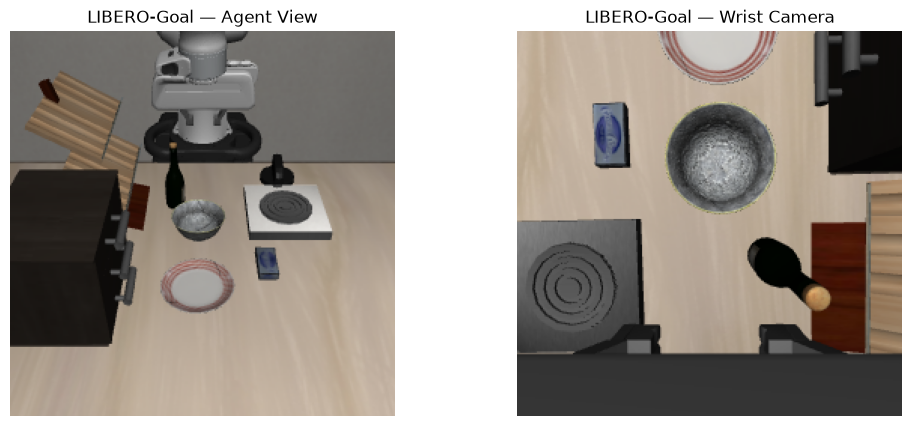

In [63]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(np.flipud(goal_obs["agentview_image"]))
axes[0].set_title("LIBERO-Goal — Agent View")

axes[1].imshow(
    np.flipud(goal_obs["robot0_eye_in_hand_image"])
)
axes[1].set_title("LIBERO-Goal — Wrist Camera")

for ax in axes:
    ax.axis("off")

plt.show()

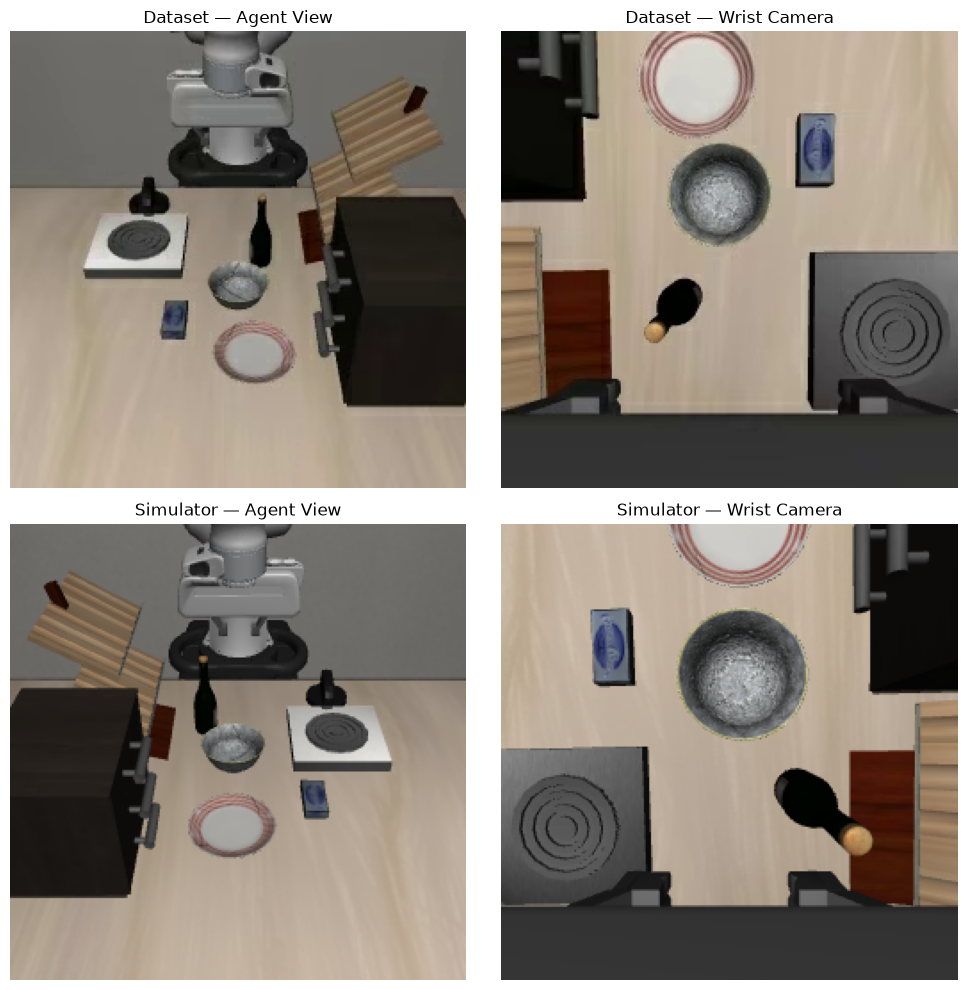

In [64]:
import matplotlib.pyplot as plt

dataset_image = (
    sample["observation.images.image"]
    .permute(1, 2, 0)
    .numpy()
)

dataset_image2 = (
    sample["observation.images.image2"]
    .permute(1, 2, 0)
    .numpy()
)

fig, axes = plt.subplots(2, 2, figsize=(10, 10))

axes[0, 0].imshow(dataset_image)
axes[0, 0].set_title("Dataset — Agent View")

axes[0, 1].imshow(dataset_image2)
axes[0, 1].set_title("Dataset — Wrist Camera")

axes[1, 0].imshow(np.flipud(goal_obs["agentview_image"]))
axes[1, 0].set_title("Simulator — Agent View")

axes[1, 1].imshow(
    np.flipud(goal_obs["robot0_eye_in_hand_image"])
)
axes[1, 1].set_title("Simulator — Wrist Camera")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

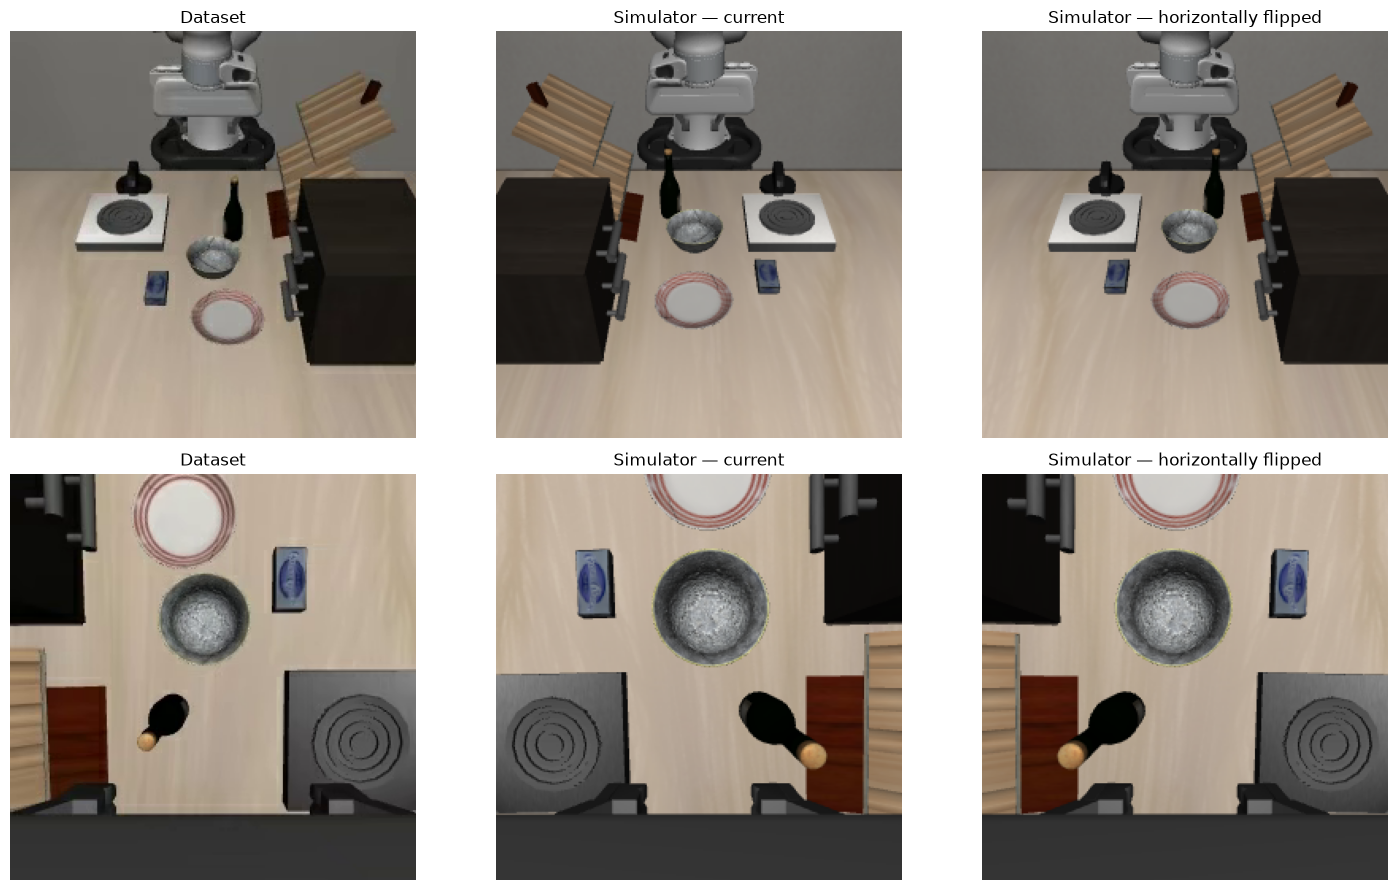

In [65]:
import numpy as np
import matplotlib.pyplot as plt

camera_keys = [
    "agentview_image",
    "robot0_eye_in_hand_image",
]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for row, key in enumerate(camera_keys):

    # Current preprocessing
    current = np.flipud(goal_obs[key])

    # Current preprocessing + horizontal flip
    mirrored = np.fliplr(current)

    # Corresponding dataset image
    dataset_key = (
        "observation.images.image"
        if row == 0
        else "observation.images.image2"
    )

    recorded = (
        sample[dataset_key]
        .permute(1, 2, 0)
        .numpy()
    )

    axes[row, 0].imshow(recorded)
    axes[row, 0].set_title("Dataset")

    axes[row, 1].imshow(current)
    axes[row, 1].set_title("Simulator — current")

    axes[row, 2].imshow(mirrored)
    axes[row, 2].set_title("Simulator — horizontally flipped")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

### 14.3 Finding the Original Evaluation Pipeline

Before implementing a custom LIBERO-to-ACT adapter,
we investigate the evaluation configuration associated
with the pretrained checkpoint.

Our goal is to identify the original environment setup
and observation processing pipeline.

This will help us reproduce the training conditions
without introducing arbitrary transformations.

In [66]:
import json
from huggingface_hub import hf_hub_download

config_path = hf_hub_download(
    repo_id=model_id,
    filename="train_config.json",
)

with open(config_path) as f:
    train_config = json.load(f)

for key, value in train_config.items():
    if any(term in key.lower() for term in [
        "env", "eval", "policy", "processor"
    ]):
        print(f"\n{key}:")
        print(json.dumps(value, indent=2)[:4000])


env:
{
  "type": "libero",
  "task": "libero_goal",
  "fps": 30,
  "features": {
    "action": {
      "type": "ACTION",
      "shape": [
        7
      ]
    },
    "pixels/agentview_image": {
      "type": "VISUAL",
      "shape": [
        256,
        256,
        3
      ]
    },
    "pixels/robot0_eye_in_hand_image": {
      "type": "VISUAL",
      "shape": [
        256,
        256,
        3
      ]
    },
    "robot_state/eef/pos": {
      "type": "STATE",
      "shape": [
        3
      ]
    },
    "robot_state/eef/quat": {
      "type": "STATE",
      "shape": [
        4
      ]
    },
    "robot_state/eef/mat": {
      "type": "STATE",
      "shape": [
        3,
        3
      ]
    },
    "robot_state/gripper/qpos": {
      "type": "STATE",
      "shape": [
        2
      ]
    },
    "robot_state/gripper/qvel": {
      "type": "STATE",
      "shape": [
        2
      ]
    },
    "robot_state/joints/pos": {
      "type": "STATE",
      "shape": [
        7
     

### 14.4 Inspecting the Official LeRobot Evaluation Pipeline

The checkpoint training configuration specifies the
LeRobot LIBERO environment adapter, task ID 8,
official initial states, and relative control.

However, the environment feature mapping exposes
structured robot states, while ACT expects a flat
8-dimensional state vector.

We will inspect LeRobot's evaluation entry point and
environment processor integration to determine how
these representations are connected.

In [67]:
import inspect

from lerobot.scripts import eval as lerobot_eval

print("Evaluation module:")
print(inspect.getfile(lerobot_eval))

print("\nRelevant functions:")
for name, obj in inspect.getmembers(lerobot_eval):
    if inspect.isfunction(obj) and any(
        term in name.lower()
        for term in ["eval", "rollout", "policy"]
    ):
        print(name, inspect.signature(obj))

ImportError: cannot import name 'eval' from 'lerobot.scripts' (unknown location)

In [68]:
import importlib
import pkgutil
import lerobot

print("LeRobot path:")
print(list(lerobot.__path__))

print("\nEvaluation-related modules:")

modules = sorted(
    module.name
    for module in pkgutil.walk_packages(
        lerobot.__path__,
        prefix="lerobot.",
    )
    if any(
        keyword in module.name.lower()
        for keyword in ["eval", "rollout", "libero"]
    )
)

for module in modules:
    print(module)

LeRobot path:
['/home/terreran/playground_ws/robot-learning-playground/.pixi/envs/cuda/lib/python3.12/site-packages/lerobot']

Evaluation-related modules:
lerobot.configs.eval
lerobot.envs.libero
lerobot.rl.eval_policy
lerobot.rollout
lerobot.rollout.configs
lerobot.rollout.context
lerobot.rollout.inference
lerobot.rollout.inference.base
lerobot.rollout.inference.factory
lerobot.rollout.inference.rtc
lerobot.rollout.inference.sync
lerobot.rollout.ring_buffer
lerobot.rollout.robot_wrapper
lerobot.rollout.strategies
lerobot.rollout.strategies.base
lerobot.rollout.strategies.core
lerobot.rollout.strategies.dagger
lerobot.rollout.strategies.episodic
lerobot.rollout.strategies.factory
lerobot.rollout.strategies.highlight
lerobot.rollout.strategies.sentry


### 14.3 Dataset Episode and Simulator Comparison

We inspect the metadata of a recorded LIBERO demonstration
and compare its initial observation with the simulator.

The goal is to identify the recorded task, episode, and
initial robot state before attempting a frame-by-frame comparison.

In [70]:
dataset = LeRobotDataset(
    repo_id="lerobot/libero",
    episodes=[training_episode],
    video_backend="pyav",
)

print(training_episode)
sample = dataset[0]

Fetching 4 files: 100%|██████████| 4/4 [00:00<00:00, 963.16it/s]

379


In [71]:
print("Dataset sample")
print("--------------")
print("Task:", sample["task"])
print("Episode:", sample["episode_index"].item())
print("Frame:", sample["frame_index"].item())
print("Timestamp:", sample["timestamp"].item())

print("\nRecorded observation.state:")
print(sample["observation.state"].numpy())

print("\nRecorded action:")
print(sample["action"].numpy())

print("\nSimulator task:")
print(goal_task.language)

print("\nSimulator initial state:")
print(make_act_observation(goal_obs)["observation.state"][0].numpy())

Dataset sample
--------------
Task: put the bowl on the plate
Episode: 379
Frame: 0
Timestamp: 0.0

Recorded observation.state:
[-0.20300905  0.01033242  1.177666    3.1398387   0.00431274 -0.09276684
  0.0387873  -0.03878865]

Recorded action:
[ 0.07232143  0.         -0.         -0.01178571  0.04392857  0.03535714
 -1.        ]

Simulator task:
put the bowl on the plate

Simulator initial state:
[-2.0556474e-01  2.3283095e-03  1.1813409e+00 -3.1254778e+00
  3.2061372e-02  7.0509598e-02  2.0833001e-02 -2.0833001e-02]


### 14.4 ACT Prediction on a Recorded Expert Observation

We evaluate the pretrained ACT policy on the first
observation of a recorded expert demonstration.

Using the dataset observation directly eliminates
uncertainties related to simulator camera conventions
and robot state reconstruction.

We compare the first predicted action with the
corresponding expert action.

The actions are not expected to be identical:
behavioral cloning learns a policy rather than
memorizing individual demonstrations.

In [72]:
# Build a batch directly from the recorded dataset sample.
dataset_obs = {
    key: sample[key].unsqueeze(0)
    for key in [
        "observation.images.image",
        "observation.images.image2",
        "observation.state",
    ]
}

policy.reset()

with torch.inference_mode():
    processed_obs = preprocessor(dataset_obs)
    predicted_action = policy.select_action(processed_obs)
    predicted_action = postprocessor(predicted_action)

predicted = predicted_action.squeeze(0).cpu().numpy()
expert = sample["action"].cpu().numpy()

print("Expert action:   ", np.round(expert, 4))
print("ACT prediction:  ", np.round(predicted, 4))
print("Difference:      ", np.round(predicted - expert, 4))
print("L2 error:        ", np.linalg.norm(predicted - expert))

Expert action:    [ 0.0723  0.     -0.     -0.0118  0.0439  0.0354 -1.    ]
ACT prediction:   [ 0.3462  0.1257 -0.1338 -0.0124  0.029  -0.0052 -1.0768]
Difference:       [ 0.2739  0.1257 -0.1338 -0.0006 -0.0149 -0.0406 -0.0768]
L2 error:         0.3412866


(3, 256, 256)


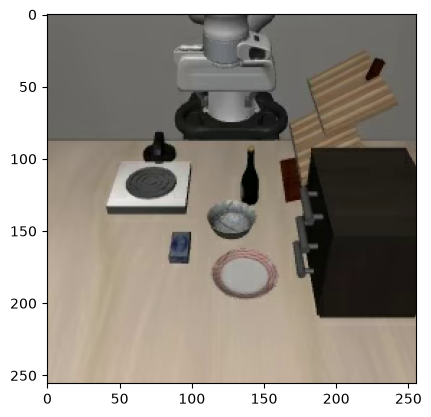

Available initial states: 50


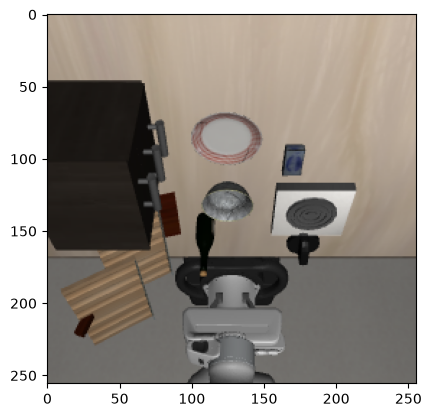

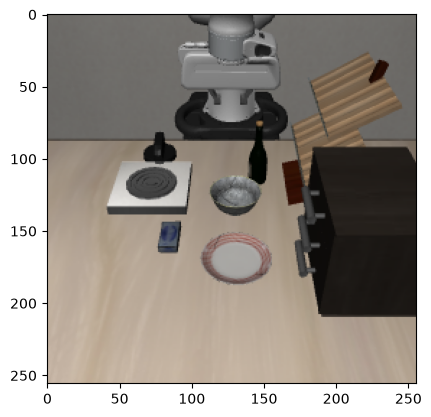

In [81]:
print(sample["observation.images.image"].numpy().shape)

plt.imshow((sample["observation.images.image"].permute(1, 2, 0).numpy()))
plt.show("Dataset — Agent View")
# Check FiftyOne, same image with robot flipped horizontally


goal_env.seed(42)
goal_obs = goal_env.reset()

# Use an initial state provided by the benchmark.
init_states = goal_suite.get_task_init_states(goal_task_id)

print("Available initial states:", len(init_states))

goal_obs = goal_env.set_init_state(init_states[0])

plt.imshow((goal_obs["agentview_image"]))
plt.show()

plt.imshow(np.rot90(goal_obs["agentview_image"], 2))
plt.show()

## 15. Closed-Loop ACT Rollout in LIBERO

We evaluate the pretrained ACT policy in the
LIBERO-Goal "put the bowl on the plate" task.

At each simulation step, the policy provides an action.
ACT internally predicts chunks of 100 actions and
executes them sequentially.

We record:

- RGB observations.
- End-effector positions.
- Predicted actions.
- Task success.

The rollout will reveal whether the policy can
complete the manipulation task in simulation.

In [82]:
def make_act_observation(raw_obs):

    def image_to_tensor(img):
        # Match the image orientation observed in the dataset.
        img = np.rot90(img, 2).copy()

        return (
            torch.from_numpy(img)
            .permute(2, 0, 1)
            .unsqueeze(0)
            .float()
            / 255.0
        )

    rotvec = Rotation.from_quat(
        raw_obs["robot0_eef_quat"]
    ).as_rotvec()

    state = np.concatenate([
        raw_obs["robot0_eef_pos"],
        rotvec,
        raw_obs["robot0_gripper_qpos"],
    ]).astype(np.float32)

    return {
        "observation.images.image": image_to_tensor(
            raw_obs["agentview_image"]
        ),
        "observation.images.image2": image_to_tensor(
            raw_obs["robot0_eye_in_hand_image"]
        ),
        "observation.state": torch.from_numpy(
            state
        ).unsqueeze(0),
    }

In [ ]:
from PIL import Image
from IPython.display import display
import numpy as np
import torch

# Reset to an official LIBERO initial state.
goal_obs = goal_env.reset()
goal_obs = goal_env.set_init_state(init_states[0])

policy.reset()

frames = []
actions = []
eef_positions = []
gripper_positions = []

max_steps = 300
success = False

for step in range(max_steps):

    # Record a frame for visualization.
    if step % 3 == 0:
        frames.append(
            Image.fromarray(
                np.flipud(
                    goal_obs["agentview_image"]
                ).copy()
            )
        )

    eef_positions.append(
        goal_obs["robot0_eef_pos"].copy()
    )

    # Build ACT input.
    policy_obs = make_act_observation(goal_obs)

    # Predict the next action.
    with torch.inference_mode():
        processed_obs = preprocessor(policy_obs)
        action = policy.select_action(processed_obs)
        action = postprocessor(action)

    action_np = (
        action.squeeze(0)
        .cpu()
        .numpy()
    )

    # Respect the simulator action bounds.
    action_np = np.clip(action_np, -1.0, 1.0)

    actions.append(action_np.copy())

    gripper_positions.append(
        goal_obs["robot0_gripper_qpos"].copy()
    )

    # Execute action in MuJoCo.
    goal_obs, reward, done, info = goal_env.step(
        action_np
    )

    success = bool(goal_env.check_success())

    if success:
        print(f"SUCCESS at step {step + 1}")
        break

    if done:
        print(f"Episode terminated at step {step + 1}")
        break

print("Steps executed:", len(actions))
print("Task success:", success)

Steps executed: 300
Task success: False


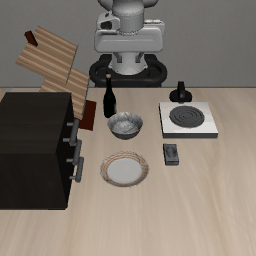

In [89]:
gif_path = "act_libero_goal_rollout.gif"

frames[0].save(
    gif_path,
    save_all=True,
    append_images=frames[1:],
    duration=100,
    loop=0,
)

display(Image.open(gif_path))

### 15.1 Diagnosing a Failed Rollout

The first ACT rollout did not complete the task, and
the robot appears stationary in the recorded video.

Before changing the policy, we analyze the recorded
actions and end-effector positions.

This allows us to distinguish between:

- A policy producing near-zero actions.
- Actions being clipped or saturated.
- A simulator that does not respond to commands.
- Small movements that are difficult to see in the video.

In [88]:
actions_np = np.asarray(actions)
eef_np = np.asarray(eef_positions)

print("Actions shape:", actions_np.shape)
print("EEF positions shape:", eef_np.shape)

print("\nFirst 5 actions:")
print(np.round(actions_np[:5], 4))

print("\nLast 5 actions:")
print(np.round(actions_np[-5:], 4))

print("\nMean absolute action:")
print(np.round(np.mean(np.abs(actions_np), axis=0), 4))

print("\nAction min:")
print(np.round(actions_np.min(axis=0), 4))

print("\nAction max:")
print(np.round(actions_np.max(axis=0), 4))

print("\nInitial EEF position:", eef_np[0])
print("Final EEF position:  ", eef_np[-1])

print("\nTotal displacement [m]:")
print(np.linalg.norm(eef_np[-1] - eef_np[0]))

print("\nMaximum displacement from initial [m]:")
print(
    np.max(
        np.linalg.norm(
            eef_np - eef_np[0],
            axis=1,
        )
    )
)

Actions shape: (300, 7)
EEF positions shape: (300, 3)

First 5 actions:
[[ 0.6505  0.1377  0.0652 -0.0147  0.0242 -0.0153 -1.    ]
 [ 0.7226  0.1665  0.0669 -0.0154  0.0337 -0.0123 -1.    ]
 [ 0.7752  0.1646  0.0707 -0.0127  0.0238 -0.0128 -1.    ]
 [ 0.8139  0.1901  0.0467 -0.0144  0.0302 -0.014  -1.    ]
 [ 0.8268  0.1678  0.0244 -0.0134  0.0334 -0.015  -1.    ]]

Last 5 actions:
[[-0.0988 -0.0677 -0.1332 -0.0137 -0.0341 -0.0063 -0.3978]
 [-0.1144 -0.037   0.011  -0.0167  0.0487 -0.0211 -0.6996]
 [-0.1258 -0.0358  0.1766 -0.0163  0.0694 -0.0249 -0.9364]
 [-0.1666 -0.0477  0.0873 -0.0205  0.02   -0.0113 -1.    ]
 [-0.0603 -0.0641  0.0405 -0.0125 -0.0092 -0.0117 -0.4568]]

Mean absolute action:
[0.212  0.0586 0.328  0.0244 0.0528 0.0207 0.7118]

Action min:
[-0.4394 -0.1451 -0.8008 -0.064  -0.1021 -0.0569 -1.    ]

Action max:
[0.9037 0.1901 0.8581 0.0838 0.137  0.0634 1.    ]

Initial EEF position: [-0.20556474  0.00232831  1.18134096]
Final EEF position:   [ 0.03278    -0.06614021  1

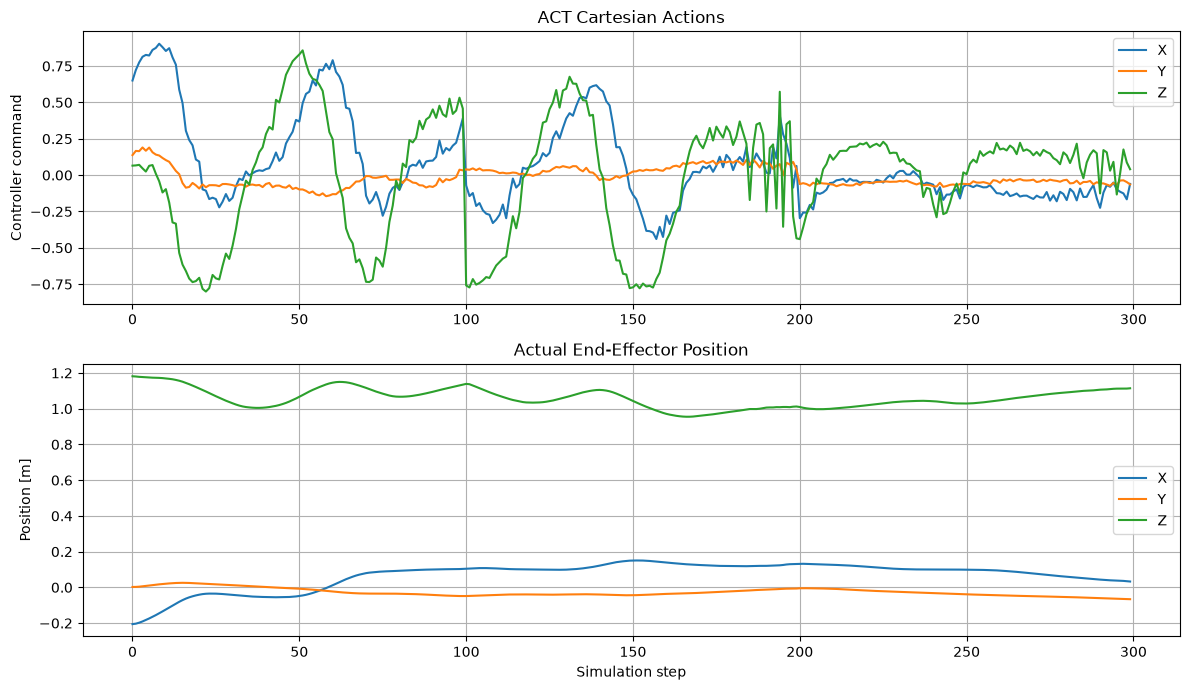

In [90]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(12, 7))

axes[0].plot(actions_np[:, :3])
axes[0].set_title("ACT Cartesian Actions")
axes[0].set_ylabel("Controller command")
axes[0].legend(["X", "Y", "Z"])
axes[0].grid(True)

axes[1].plot(eef_np)
axes[1].set_title("Actual End-Effector Position")
axes[1].set_xlabel("Simulation step")
axes[1].set_ylabel("Position [m]")
axes[1].legend(["X", "Y", "Z"])
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [91]:
import imageio.v2 as imageio
from IPython.display import Video, display
import numpy as np

video_path = "act_libero_goal_rollout.mp4"

with imageio.get_writer(
    video_path,
    fps=10,
    codec="libx264",
    macro_block_size=16,
) as writer:
    for frame in frames:
        writer.append_data(np.asarray(frame.convert("RGB")))

display(Video(video_path, embed=True))

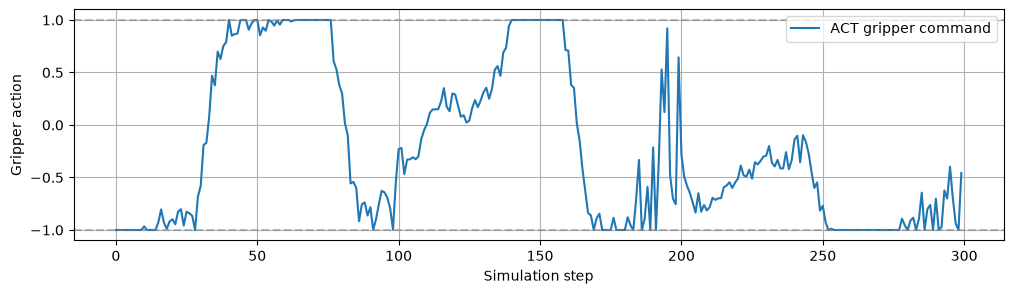

First 20 gripper actions:
[-1.    -1.    -1.    -1.    -1.    -1.    -1.    -1.    -1.    -1.
 -0.966 -1.    -1.    -1.    -1.    -0.928 -0.804 -0.931 -0.989 -0.918]
Last 20 gripper actions:
[-1.    -0.911 -0.883 -1.    -0.895 -0.645 -1.    -0.801 -0.762 -1.
 -0.702 -1.    -0.97  -0.623 -0.7   -0.398 -0.7   -0.936 -1.    -0.457]


In [92]:
import numpy as np
import matplotlib.pyplot as plt

actions_np = np.asarray(actions)

plt.figure(figsize=(12, 3))
plt.plot(actions_np[:, 6], label="ACT gripper command")
plt.axhline(-1, color="gray", linestyle="--", alpha=0.5)
plt.axhline(+1, color="gray", linestyle="--", alpha=0.5)
plt.xlabel("Simulation step")
plt.ylabel("Gripper action")
plt.legend()
plt.grid(True)
plt.show()

print("First 20 gripper actions:")
print(np.round(actions_np[:20, 6], 3))

print("Last 20 gripper actions:")
print(np.round(actions_np[-20:, 6], 3))

In [93]:
gripper_positions = []

# All'interno del ciclo, prima di goal_env.step(...)
gripper_positions.append(
    goal_obs["robot0_gripper_qpos"].copy()
)